Found 12632 files belonging to 6 classes.
Using 10106 files for training.
Found 12632 files belonging to 6 classes.
Using 2526 files for validation.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5


c:\study materials\LP-4\solution\.lab\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


316/316 ━━━━━━━━━━━━━━━━━━━━ 132s 387ms/step - accuracy: 0.8719 - loss: 0.3449 - val_accuracy: 0.9082 - val_loss: 0.2538
Epoch 2/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 114s 360ms/step - accuracy: 0.9200 - loss: 0.2149 - val_accuracy: 0.9149 - val_loss: 0.2348
Epoch 3/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 103s 327ms/step - accuracy: 0.9305 - loss: 0.1811 - val_accuracy: 0.9125 - val_loss: 0.2483
Epoch 4/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 104s 329ms/step - accuracy: 0.9415 - loss: 0.1541 - val_accuracy: 0.9169 - val_loss: 0.2470
Epoch 5/5
316/316 ━━━━━━━━━━━━━━━━━━━━ 107s 337ms/step - accuracy: 0.9508 - loss: 0.1303 - val_accuracy: 0.9161 - val_loss: 0.2742
79/79 ━━━━━━━━━━━━━━━━━━━━ 21s 268ms/step - accuracy: 0.9161 - loss: 0.2742
Test Loss: 0.2741638123989105
Test Accuracy: 0.9160728454589844
Epoch 1/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 164s 495ms/step - accuracy: 0.9176 - loss: 0.2232 - val_accuracy: 0.9117 - val_loss: 0.2399
Epoch 2/3
316/316 ━━━━━━━━━━━━━━━━━━━━ 158s 500ms/step - accuracy: 0.9448 - loss: 0.

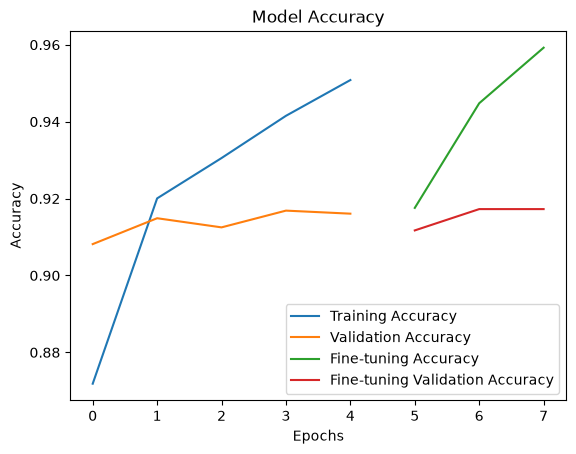

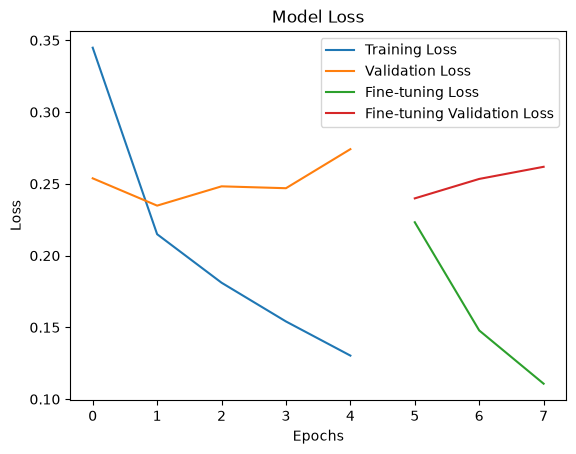

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


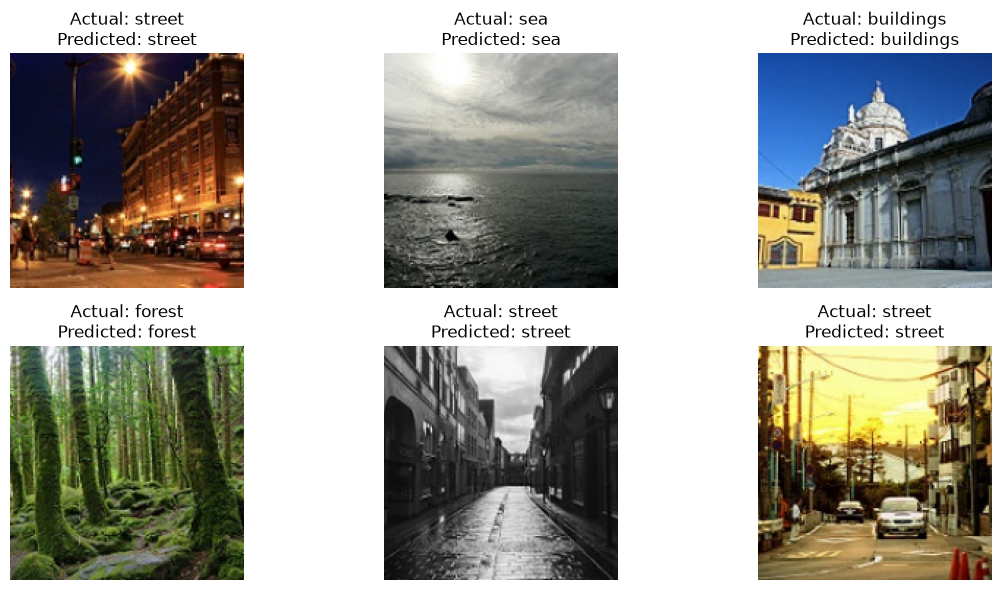

Model saved successfully!


In [1]:

# Practical 5B: Transfer Learning using MobileNetV2
# Intel Image Classification Dataset (Local Dataset)

# STEP 1: Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# STEP 2: Set local dataset path
dataset_path = "Intel Image Classification"

IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32

# STEP 3: Load local training dataset (80%)
train_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=123
)

# STEP 4: Load local testing/validation dataset (20%)
test_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=123
)

class_names = train_data.class_names
print("Classes:", class_names)

# STEP 5: Preprocess images for MobileNetV2
train_data = train_data.map(
    lambda x, y: (preprocess_input(x), y)
)

test_data = test_data.map(
    lambda x, y: (preprocess_input(x), y)
)

# STEP 6: Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# STEP 7: Add custom classification layers
model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

# STEP 8: Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# STEP 9: Train model
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=5
)

# STEP 10: Evaluate model
loss, accuracy = model.evaluate(test_data)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# STEP 11: Fine-tuning
base_model.trainable = True

# Freeze all layers except last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Compile with a small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train fine-tuned model
fine_history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=3
)

# STEP 12: Evaluate fine-tuned model
loss, accuracy = model.evaluate(test_data)

print("Fine-tuned Loss:", loss)
print("Fine-tuned Accuracy:", accuracy)

# STEP 13: Plot accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.plot(np.arange(5, 8), fine_history.history["accuracy"], label="Fine-tuning Accuracy")
plt.plot(np.arange(5, 8), fine_history.history["val_accuracy"], label="Fine-tuning Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# STEP 14: Plot loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.plot(np.arange(5, 8), fine_history.history["loss"], label="Fine-tuning Loss")
plt.plot(np.arange(5, 8), fine_history.history["val_loss"], label="Fine-tuning Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# STEP 15: Visualize predictions
for images, labels in test_data.take(1):

    predictions = model.predict(images)
    predicted_labels = np.argmax(predictions, axis=1)

    plt.figure(figsize=(12, 6))

    for i in range(6):
        plt.subplot(2, 3, i + 1)

        # Convert image back for display
        display_image = (images[i].numpy() + 1) * 127.5
        display_image = np.clip(display_image, 0, 255).astype("uint8")

        plt.imshow(display_image)

        actual = class_names[labels[i].numpy()]
        predicted = class_names[predicted_labels[i]]

        plt.title("Actual: " + actual + "\nPredicted: " + predicted)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# STEP 16: Save model
model.save("intel_transfer_learning_model.keras")

print("Model saved successfully!")


# Practical 5B – Object Detection using Transfer Learning with CNN (MobileNetV2)

Problem Statement: Object detection using Transfer Learning of CNN architectures for the Intel Image Classification Dataset.

Steps:

1. Set up the environment.
2. Load and preprocess data.
3. Choose a pre-trained model.
4. Freeze base layers and add custom layers.
5. Train the model.
6. Compute loss.
7. Evaluate the model.
8. Visualize predictions.
9. Fine-tune the model by unfreezing the top pre-trained layers and retraining.

## 1. First understand the logic

The main aim of this practical is to classify images into different categories using a pre-trained CNN model called MobileNetV2.

Suppose the Intel dataset contains images of:

- Buildings
- Forest
- Glacier
- Mountain
- Sea
- Street

The computer needs to identify which category an image belongs to.

Normally, we would train a CNN from scratch. But that takes more time and data.

Instead, we use MobileNetV2, which is already trained on ImageNet.

It has already learned how to recognize image features such as edges, shapes, textures and patterns.

We reuse this knowledge and train additional layers to recognize the six Intel image categories.

[Quality Grading Algorithm of Oudemansiella raphanipes Based on Transfer Learning and MobileNetV2 | MDPI](https://images.openai.com/static-rsc-4/siJD9oA5GsjpSHH40xYMperCdAvVli_OQpRQd4jP_0X7j42uCcpPcL3s1tfwGatvcQxPGhc0QItJ97kH6TEGQfs2bb6uZkC1v22uXtRl1ZhvhTliOn54v2wXxqBhFsNPcpDAdSnJ45AvvOhgrrDIA5KNt0AZigEg9J6uwxj4TCk?purpose=inline)

### Overall working

Intel Image Classification Dataset

Resize and preprocess images

Load pre-trained MobileNetV2

Freeze base layers and add custom layers

Train and evaluate model

Fine-tune last 30 layers

Predict image categories and save model

Important clarification: Like Practical 5A, your code performs image classification, not full object detection. It predicts one category for each image; it does not locate objects using bounding boxes.

## 2. Code explanation step by step

### Step 1: Import libraries

```
import tensorflow as tfimport numpy as npimport matplotlib.pyplot as pltfrom tensorflow.keras import layers, modelsfrom tensorflow.keras.applications import MobileNetV2from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
```

- `tensorflow`: Used to build and train the deep learning model.
- `numpy`: Used for numerical calculations.
- `matplotlib`: Displays images and graphs.
- `layers, models`: Used to create the neural network.
- `MobileNetV2`: Loads the pre-trained CNN.
- `preprocess_input`: Prepares images in the format MobileNetV2 expects.

### Step 2: Set dataset path

```
dataset_path = "Intel Image Classification"IMAGE_SIZE = (160, 160)BATCH_SIZE = 32
```

- `dataset_path`: Location of your local dataset.
- `IMAGE_SIZE`: Every image is resized to 160 × 160 pixels.
- `BATCH_SIZE=32`: The model processes 32 images at a time.

What is a batch?

Instead of processing the entire dataset at once, the model processes small groups of images. Here, each group contains 32 images.

### Step 3: Load training dataset

```
train_data = tf.keras.utils.image_dataset_from_directory(    dataset_path,    image_size=IMAGE_SIZE,    batch_size=BATCH_SIZE,    validation_split=0.2,    subset="training",    seed=123)
```

This loads images from your local Intel dataset folder.

Your folder should look approximately like this:

```
Intel Image Classification/
    buildings/
    forest/
    glacier/
    mountain/
    sea/
    street/
```

Explanation:

| Parameter              | Meaning                       |
| ---------------------- | ----------------------------- |
| `dataset_path`         | Dataset folder                |
| `image_size`           | Resizes images to 160 × 160   |
| `batch_size`           | Processes 32 images at a time |
| `validation_split=0.2` | Reserves 20% for validation   |
| `subset="training"`    | Loads 80% training images     |
| `seed=123`             | Keeps the split consistent    |

### Step 4: Load testing/validation dataset

```
test_data = tf.keras.utils.image_dataset_from_directory(    dataset_path,    image_size=IMAGE_SIZE,    batch_size=BATCH_SIZE,    validation_split=0.2,    subset="validation",    seed=123)
```

Loads the remaining 20% of images.

In this code, the variable is called `test_data`, but technically it is a validation dataset, because it is being used during training to monitor performance.

### Step 5: Get class names

```
class_names = train_data.class_namesprint("Classes:", class_names)
```

Automatically identifies the image categories from the folder names.

For example:

```
['buildings', 'forest', 'glacier',
 'mountain', 'sea', 'street']
```

There are six categories in this example.

### Step 6: Preprocess images for MobileNetV2

```
train_data = train_data.map(    lambda x, y: (preprocess_input(x), y))test_data = test_data.map(    lambda x, y: (preprocess_input(x), y))
```

This is an important step.

MobileNetV2 expects images to be preprocessed in a particular way.

`preprocess_input()` scales the pixel values from the normal image range (0 to 255) to approximately (-1 to 1).

- `x` represents images.
- `y` represents their correct class labels.
- `map()` applies preprocessing to every batch.

Why do we need this?

Because the pre-trained MobileNetV2 model was trained using this particular image preprocessing method. We should use the same method for our images.

### Step 7: Load pre-trained MobileNetV2

```
base_model = MobileNetV2(    weights="imagenet",    include_top=False,    input_shape=(160, 160, 3))
```

This loads the already-trained MobileNetV2 model.

| Parameter            | Meaning                                    |
| -------------------- | ------------------------------------------ |
| `MobileNetV2`        | CNN architecture                           |
| `weights="imagenet"` | Uses previously learned ImageNet weights   |
| `include_top=False`  | Removes the original classification layers |
| `input_shape`        | Accepts 160 × 160 RGB images               |

What is MobileNetV2?

It is a lightweight CNN architecture designed to perform image recognition efficiently, especially on devices with limited computing resources.

Why `include_top=False`?

The original model was trained to classify ImageNet categories. We remove its original output layers because we want to classify Intel dataset categories instead.

### Step 8: Freeze pre-trained layers

```
base_model.trainable = False
```

Freezes all the MobileNetV2 layers.

This means their existing weights will not change during the initial training.

Why?

Because MobileNetV2 already knows how to extract useful image features. We want to reuse those features and train our own classification layers.

### Step 9: Add custom classification layers

```
model = models.Sequential([    layers.Input(shape=(160, 160, 3)),    base_model,    layers.GlobalAveragePooling2D(),    layers.Dense(128, activation="relu"),    layers.Dropout(0.3),    layers.Dense(len(class_names), activation="softmax")])
```

Let's understand each layer.

1\. Input layer

```
layers.Input(shape=(160, 160, 3))
```

Accepts an image of size 160 × 160 with three RGB channels.

2\. MobileNetV2

```
base_model
```

Extracts image features such as edges, shapes, textures and patterns.

3\. GlobalAveragePooling2D

```
layers.GlobalAveragePooling2D()
```

Converts the feature maps into a one-dimensional vector.

4\. Dense layer

```
layers.Dense(128, activation="relu")
```

Learns patterns from the extracted image features using 128 neurons.

5\. Dropout layer

```
layers.Dropout(0.3)
```

Randomly switches off 30% of the neurons during training.

Why?

To reduce overfitting.

Overfitting happens when a model performs well on training data but poorly on unseen data.

6\. Output layer

```
layers.Dense(len(class_names), activation="softmax")
```

Creates one output neuron for each category.

If there are six categories, it creates six output neurons.

`softmax` produces the probability of each category.

For example:

| Class     | Example probability |
| --------- | ------------------- |
| Buildings | 0.05                |
| Forest    | 0.10                |
| Glacier   | 0.05                |
| Mountain  | 0.70                |
| Sea       | 0.05                |
| Street    | 0.05                |

The predicted category is Mountain because it has the highest probability.

### Step 10: Compile the model

```
model.compile(    optimizer="adam",    loss="sparse_categorical_crossentropy",    metrics=["accuracy"])
```

Before training, we configure how the model learns.

- `optimizer="adam"`: Updates weights to reduce prediction errors.
- `loss="sparse_categorical_crossentropy"`: Measures prediction error for multiple classes with integer labels.
- `metrics=["accuracy"]`: Measures how many images are classified correctly.

### Step 11: Display model summary

```
model.summary()
```

Displays all layers, output shapes and the number of trainable and non-trainable parameters.

### Step 12: Train the model

```
history = model.fit(    train_data,    validation_data=test_data,    epochs=5)
```

This is where the model learns.

- `train_data`: Images used for training.
- `validation_data`: Images used to check model performance.
- `epochs=5`: The model goes through the training dataset five times.

During this stage, MobileNetV2 remains frozen, so the custom classification layers learn from its extracted features.

### Step 13: Evaluate the model

```
loss, accuracy = model.evaluate(test_data)print("Test Loss:", loss)print("Test Accuracy:", accuracy)
```

Checks how well the model performs on the validation dataset.

- Loss tells us the prediction error.
- Accuracy tells us the percentage of correct predictions.

For example, 90% accuracy means approximately 90 out of 100 images were classified correctly.

### Step 14: Fine-tuning the model

This is the second training stage.

Initially, all MobileNetV2 layers were frozen. Now we want the model to adapt some of its pre-trained features to Intel images.

```
base_model.trainable = True
```

Unfreezes the MobileNetV2 model.

But we don't want to train every layer, so:

```
for layer in base_model.layers[:-30]:    layer.trainable = False
```

This freezes all layers except the last 30.

In simple words:

- Earlier: All MobileNetV2 layers were frozen.
- Now: Only the last 30 layers are allowed to learn.

Why do we do this?

Because the model already knows general image features. We only want some of its later layers to adapt to our new dataset.

Next:

```
for layer in base_model.layers:    if isinstance(layer, layers.BatchNormalization):        layer.trainable = False
```

This keeps Batch Normalization layers frozen.

Batch Normalization helps keep the values flowing through the network stable. Keeping these layers frozen can make fine-tuning more stable, especially with smaller datasets.

Now compile again:

```
model.compile(    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),    loss="sparse_categorical_crossentropy",    metrics=["accuracy"])
```

Why compile again?

Because we have changed which layers are trainable. We need to recompile the model for these changes to take effect.

Why use `learning_rate=0.0001`?

It makes smaller weight updates during fine-tuning, helping preserve the useful features learned by MobileNetV2.

Finally:

```
fine_history = model.fit(    train_data,    validation_data=test_data,    epochs=3)
```

Trains the model again for three epochs with the last 30 MobileNetV2 layers unfrozen.

### Step 15: Evaluate the fine-tuned model

```
loss, accuracy = model.evaluate(test_data)print("Fine-tuned Loss:", loss)print("Fine-tuned Accuracy:", accuracy)
```

Checks the model's performance after fine-tuning.

We can compare the accuracy before and after fine-tuning to see whether it improved.

### Step 16: Plot accuracy

```
plt.plot(history.history["accuracy"], label="Training Accuracy")plt.plot(history.history["val_accuracy"], label="Validation Accuracy")plt.plot(np.arange(5, 8), fine_history.history["accuracy"], label="Fine-tuning Accuracy")plt.plot(np.arange(5, 8), fine_history.history["val_accuracy"], label="Fine-tuning Validation Accuracy")plt.title("Model Accuracy")plt.xlabel("Epochs")plt.ylabel("Accuracy")plt.legend()plt.show()
```

This graph displays the training and validation accuracy across both training stages.

- First five epochs: Initial training.
- Next three epochs: Fine-tuning.

`np.arange(5, 8)` generates the epoch positions 5, 6 and 7 for the fine-tuning graphs.

### Step 17: Plot loss

```
plt.plot(history.history["loss"], label="Training Loss")plt.plot(history.history["val_loss"], label="Validation Loss")plt.plot(np.arange(5, 8), fine_history.history["loss"], label="Fine-tuning Loss")plt.plot(np.arange(5, 8), fine_history.history["val_loss"], label="Fine-tuning Validation Loss")plt.title("Model Loss")plt.xlabel("Epochs")plt.ylabel("Loss")plt.legend()plt.show()
```

Displays how the model's prediction error changes during training and fine-tuning.

Generally:

- Lower training loss is desirable.
- Lower validation loss is desirable.
- A large gap between training and validation performance may indicate overfitting.

### Step 18: Visualize predictions

```
for images, labels in test_data.take(1):    predictions = model.predict(images)    predicted_labels = np.argmax(predictions, axis=1)
```

- `test_data.take(1)`: Takes one batch of images.
- `model.predict(images)`: Predicts the categories of those images.
- `np.argmax(..., axis=1)`: Selects the category with the highest probability for each image.

Next:

```
plt.figure(figsize=(12, 6))for i in range(6):    plt.subplot(2, 3, i + 1)
```

Creates a figure and divides it into six positions (2 rows and 3 columns).

```
display_image = (images[i].numpy() + 1) * 127.5display_image = np.clip(display_image, 0, 255).astype("uint8")
```

Remember, earlier we converted the image values from 0–255 to approximately -1 to 1 using `preprocess_input()`.

Now we reverse that transformation to display the image properly.

- `+1`: Shifts values back.
- `*127.5`: Converts values back to the 0–255 range.
- `np.clip()`: Keeps pixel values between 0 and 255.
- `astype("uint8")`: Converts values into image-compatible integers.

Then:

```
plt.imshow(display_image)actual = class_names[labels[i].numpy()]predicted = class_names[predicted_labels[i]]plt.title("Actual: " + actual + "\nPredicted: " + predicted)plt.axis("off")
```

Displays each image with:

- Actual category: Correct dataset label.
- Predicted category: Model's prediction.

This lets us visually check whether the model is classifying images correctly.

### Step 19: Save the model

```
model.save("intel_transfer_learning_model.keras")print("Model saved successfully!")
```

Saves the final fine-tuned model.

We can load it later using:

```
model = tf.keras.models.load_model(    "intel_transfer_learning_model.keras")
```

## 3. Understand the two training stages

This is one of the most important viva topics.

Stage 1 – Feature Extraction

All base layers frozen

- Load MobileNetV2 with ImageNet weights.
- Freeze all pre-trained layers.
- Add custom classification layers.
- Train for 5 epochs.

Stage 2 – Fine-tuning

Last 30 layers unfrozen

- Unfreeze MobileNetV2.
- Freeze all except the last 30 layers.
- Keep Batch Normalization layers frozen.
- Use a smaller learning rate.
- Train for 3 more epochs.

## 4. Important viva theory questions

Q1. What is Transfer Learning?

Transfer Learning is a technique where we use a model already trained on a large dataset and reuse its knowledge for a new task.

Q2. What is MobileNetV2?

MobileNetV2 is a lightweight Convolutional Neural Network designed for efficient image recognition.

Q3. Why do we use MobileNetV2 instead of training a CNN from scratch?

Because it already knows how to extract useful image features, reducing training time and the amount of data needed.

Q4. What is the Intel Image Classification dataset?

It is an image dataset containing six categories: buildings, forest, glacier, mountain, sea and street.

Q5. What is ImageNet?

ImageNet is a large image dataset used to train pre-trained image recognition models.

Q6. What is the purpose of `preprocess_input()`?

It converts image pixel values into the format expected by MobileNetV2.

Q7. What does `include_top=False` mean?

It removes the original classification layers of MobileNetV2 so we can add our own classification layers.

Q8. What is freezing?

Freezing means preventing pre-trained layers from updating their weights during training.

Q9. What is fine-tuning?

Fine-tuning means unfreezing selected pre-trained layers and training them on the new dataset.

Q10. Why do we use Dropout?

To reduce overfitting by randomly switching off some neurons during training.

Q11. What is GlobalAveragePooling2D?

It converts feature maps into a one-dimensional feature vector.

Q12. Why do we use Softmax?

To calculate class probabilities for multi-class classification.

Q13. What is Batch Normalization?

It normalizes intermediate network activations to help make training more stable.

Q14. What is the difference between VGG16 and MobileNetV2?

- VGG16 has a relatively large and computationally expensive architecture.
- MobileNetV2 is designed to be lightweight and computationally efficient.

Q15. What is the difference between feature extraction and fine-tuning?

Feature extraction trains only the newly added layers. Fine-tuning also trains selected layers of the pre-trained model.

Q16. Is this object detection or image classification?

This code performs image classification. Object detection additionally identifies the location of objects using bounding boxes.

## 5. What to explain to the examiner

You can speak this:

"I implemented Transfer Learning using MobileNetV2 on the Intel Image Classification dataset. First, I loaded the local dataset and divided it into training and validation data. I resized the images to 160 by 160 pixels and applied MobileNetV2 preprocessing.

Next, I loaded MobileNetV2 with ImageNet weights and removed its original classification layers. I froze the pre-trained layers and added Global Average Pooling, Dense, Dropout and Softmax layers for classifying the six categories.

Then I compiled and trained the model using Adam optimizer and sparse categorical crossentropy loss. I evaluated the model and plotted accuracy and loss graphs.

After initial training, I fine-tuned the model by unfreezing the last 30 layers while keeping Batch Normalization layers frozen. Finally, I visualized actual and predicted categories and saved the trained model."

## 6. Quick revision

| Concept                | Remember                        |
| ---------------------- | ------------------------------- |
| Transfer Learning      | Reusing a pre-trained model     |
| MobileNetV2            | Lightweight CNN                 |
| ImageNet               | Pre-training dataset            |
| `preprocess_input()`   | Prepares image pixels           |
| `include_top=False`    | Removes original output layers  |
| `trainable=False`      | Freezes layers                  |
| GlobalAveragePooling2D | Reduces feature maps            |
| Dropout(0.3)           | Reduces overfitting             |
| Softmax                | Predicts class probabilities    |
| Adam                   | Optimizer                       |
| Loss                   | Prediction error                |
| Fine-tuning            | Retraining selected base layers |
| Batch Normalization    | Helps stabilize training        |

## 7. Important corrections to remember

Your code is suitable for the practical demonstration. However, there are three details worth knowing:

1. Dataset split: Your variable is named `test_data`, but the code uses it as validation data during training. A completely separate test dataset would give a more independent final evaluation.
2. Fine-tuning: Fine-tuning does not guarantee improved accuracy. Compare the validation accuracy and loss before and after.
3. Preprocessing: Because `preprocess_input()` changes images to approximately -1 to 1, you correctly reverse that transformation before displaying them.

Most important concept: MobileNetV2 extracts image features, custom layers classify the six Intel categories, and fine-tuning adapts the pre-trained network to the Intel dataset.